<a href="https://colab.research.google.com/github/febriyansyah-id/LECTURES-SMTIII-PRIVATE/blob/main/SMTIII-BIG%20DATA%20ANALYSIS%20AND%20DATA%20VISUALISATION/P07-UTS/script.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Segmentasi Profitabilitas dan Efektivitas Diskon
## Menggunakan Metode K-Means Clustering

Notebook ini berisi implementasi analisis dataset Superstore dari tahap pemuatan data sampai ekspor hasil clustering.

## 1. Import Library

Library digunakan untuk membaca data, preprocessing, standardisasi, dan clustering.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.stats import kruskal, spearmanr, chi2_contingency

## 2. Upload dan Membaca Dataset

Unggah file `soal2_Superstore.csv` dari komputer ke Google Colab.

In [2]:
uploaded = files.upload()
df = pd.read_csv("soal2_Superstore.csv")
df_awal = df.copy()
print("Dimensi awal:", df.shape)
df.head()

Saving soal2_Superstore.csv to soal2_Superstore (1).csv
Dimensi awal: (10993, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,NaN,CA-2016-152156,NaN,2016-11-11,Second Class,CG-12520,Claire Gute,NaN,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,-875.182483,2.0,0.0,41.9136
1,-17884.612462,CA-2016-152156,NaN,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,NaN,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.940000,3.0,0.0,219.5820
2,3.000000,CA-2016-138688,2016-06-12,2016-06-16,Second Class,NaN,Darrin Van Huff,Corporate,NaN,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.620000,2.0,NaN,NaN
3,23128.698865,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,NaN,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,1615.636302,5.0,NaN,NaN
4,5.000000,NaN,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,NaN,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368000,2.0,0.2,2.5164


## 3. Eksplorasi Kualitas Data

Pemeriksaan meliputi tipe data, missing value, dan data duplikat.

In [3]:
print(df.info())
print("\\nMissing value:")
print(df.isna().sum())
print("\\nJumlah duplikat:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10993 entries, 0 to 10992
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9292 non-null   float64
 1   Order ID       9347 non-null   object 
 2   Order Date     9344 non-null   object 
 3   Ship Date      9312 non-null   object 
 4   Ship Mode      9364 non-null   object 
 5   Customer ID    9386 non-null   object 
 6   Customer Name  9331 non-null   object 
 7   Segment        9357 non-null   object 
 8   Country        9317 non-null   object 
 9   City           9377 non-null   object 
 10  State          9358 non-null   object 
 11  Postal Code    9419 non-null   float64
 12  Region         9325 non-null   object 
 13  Product ID     9250 non-null   object 
 14  Category       9322 non-null   object 
 15  Sub-Category   9372 non-null   object 
 16  Product Name   9393 non-null   object 
 17  Sales          9347 non-null   float64
 18  Quanti

## 4. Menghapus Data Duplikat

Baris duplikat dihapus agar transaksi yang sama tidak dihitung berulang.

In [4]:
df = df.drop_duplicates().copy()
print("Dimensi setelah deduplikasi:", df.shape)

Dimensi setelah deduplikasi: (9994, 21)


## 5. Menentukan Fitur Analisis

Empat fitur numerik digunakan untuk mengukur nilai dan profitabilitas transaksi. Dua fitur kategorikal digunakan untuk memasukkan konteks produk dan wilayah.

In [5]:
fitur_numerik = ["Sales", "Quantity", "Discount", "Profit"]
fitur_kategorikal = ["Category", "Region"]
fitur = fitur_numerik + fitur_kategorikal
df[fitur].head()

,Sales,Quantity,Discount,Profit,Category,Region
0,-875.182483,2.0,0.0,41.9136,Furniture,South
1,731.940000,3.0,0.0,219.5820,Furniture,South
2,14.620000,2.0,NaN,NaN,Office Supplies,West
3,1615.636302,5.0,NaN,NaN,Furniture,South
4,22.368000,2.0,0.2,2.5164,Office Supplies,South


## 6. Preprocessing Data

Missing value numerik diisi dengan median, missing value kategorikal diisi dengan modus, kategori diubah dengan one-hot encoding, dan fitur numerik distandardisasi.

In [6]:
preprocessor = ColumnTransformer([
    ("numerik", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), fitur_numerik),
    ("kategorikal", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), fitur_kategorikal)
])

X = preprocessor.fit_transform(df[fitur])
print("Dimensi data hasil preprocessing:", X.shape)

Dimensi data hasil preprocessing: (9994, 11)


## 7. Membentuk Model K-Means

Model menggunakan empat cluster. `random_state` digunakan agar hasil dapat direproduksi.

In [7]:
model = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(X)
print(df["Cluster"].value_counts().sort_index())

Cluster
0    1318
1      12
2    1344
3    7320
Name: count, dtype: int64


## 8. Profil dan Interpretasi Cluster

Rata-rata fitur numerik digunakan untuk memahami karakteristik setiap cluster.

In [8]:
ukuran_cluster = df["Cluster"].value_counts().sort_index()
profil_cluster = df.groupby("Cluster")[fitur_numerik].mean().round(2)
print("Ukuran cluster:")
print(ukuran_cluster)
print("\\nProfil cluster:")
print(profil_cluster)

Ukuran cluster:
Cluster
0    1318
1      12
2    1344
3    7320
Name: count, dtype: int64
\nProfil cluster:
            Sales  Quantity  Discount   Profit
Cluster                                       
0          159.57      2.72      0.82   -32.80
1        10610.80      4.75      0.09  3429.80
2          697.56     12.14      0.10    99.20
3          131.45      2.06      0.01    21.62


## 9. Validasi Model dan Pengujian Statistik

Tahap ini menghitung validasi internal cluster dan pengujian statistik untuk mendukung interpretasi hasil.

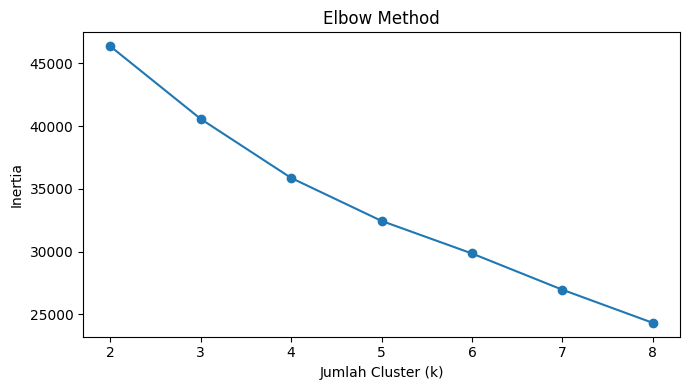

In [9]:
# 1. Elbow Method
inertia = []
k_values = range(2, 9)
for k in k_values:
    m = KMeans(n_clusters=k, random_state=42, n_init=10)
    m.fit(X)
    inertia.append(m.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig('gambar_elbow_method.png', dpi=150)
plt.show()

In [10]:
# 2. Silhouette Score, Davies-Bouldin, dan Calinski-Harabasz
validasi = []
for k in k_values:
    m = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = m.fit_predict(X)
    validasi.append({
        'k': k,
        'silhouette_score': silhouette_score(X, labels),
        'davies_bouldin_index': davies_bouldin_score(X.toarray() if hasattr(X, 'toarray') else X, labels),
        'calinski_harabasz_score': calinski_harabasz_score(X.toarray() if hasattr(X, 'toarray') else X, labels)
    })
validasi_df = pd.DataFrame(validasi).round(4)
display(validasi_df)
print('Silhouette terbaik: k =', validasi_df.loc[validasi_df['silhouette_score'].idxmax(), 'k'])
print('Davies-Bouldin terbaik: k =', validasi_df.loc[validasi_df['davies_bouldin_index'].idxmin(), 'k'])
print('Calinski-Harabasz terbaik: k =', validasi_df.loc[validasi_df['calinski_harabasz_score'].idxmax(), 'k'])

,k,silhouette_score,davies_bouldin_index,calinski_harabasz_score
0,2,0.2158,2.2780,1225.8758
1,3,0.1984,1.7249,1413.4102
2,4,0.2462,1.4137,1501.9197
3,5,0.2696,1.3745,1508.8422
4,6,0.2115,1.5186,1485.4585
5,7,0.2274,1.4460,1548.5256
6,8,0.2364,1.3209,1626.0257


Silhouette terbaik: k = 5
Davies-Bouldin terbaik: k = 8
Calinski-Harabasz terbaik: k = 8


In [11]:
# 3. Kruskal-Wallis untuk Sales, Discount, dan Profit
uji_kw = []
for kolom in ['Sales', 'Discount', 'Profit']:
    kelompok = [g[kolom].dropna().values for _, g in df.groupby('Cluster')]
    statistik, p_value = kruskal(*kelompok)
    uji_kw.append({'variabel': kolom, 'statistik_h': statistik, 'p_value': p_value, 'signifikan_0_05': p_value < 0.05})
uji_kw_df = pd.DataFrame(uji_kw).round(6)
display(uji_kw_df)

,variabel,statistik_h,p_value,signifikan_0_05
0,Sales,524.668624,0.0,True
1,Discount,3628.953472,0.0,True
2,Profit,439.589932,0.0,True


In [12]:
# 4. Korelasi Spearman Discount dan Profit
data_korelasi = df[['Discount', 'Profit']].dropna()
rho, p_value_spearman = spearmanr(data_korelasi['Discount'], data_korelasi['Profit'])
spearman_df = pd.DataFrame([{
    'variabel_x': 'Discount',
    'variabel_y': 'Profit',
    'rho_spearman': rho,
    'p_value': p_value_spearman,
    'signifikan_0_05': p_value_spearman < 0.05
}]).round(6)
display(spearman_df)

,variabel_x,variabel_y,rho_spearman,p_value,signifikan_0_05
0,Discount,Profit,-0.250314,0.0,True


In [13]:
# 5. Chi-Square Category dan Cluster
tabel_kontingensi = pd.crosstab(df['Category'].fillna('Missing'), df['Cluster'])
chi2, p_value_chi, derajat_bebas, expected = chi2_contingency(tabel_kontingensi)
chi_square_df = pd.DataFrame([{
    'chi2': chi2,
    'p_value': p_value_chi,
    'derajat_bebas': derajat_bebas,
    'signifikan_0_05': p_value_chi < 0.05
}]).round(6)
display(tabel_kontingensi)
display(chi_square_df)

Cluster,0,1,2,3
Category,,,,
Furniture,252,0,305,1249
Missing,202,4,187,1112
Office Supplies,745,2,586,3780
Technology,119,6,266,1179


,chi2,p_value,derajat_bebas,signifikan_0_05
0,113.921604,0.0,9,True


## 10. Visualisasi dan Tabel Hasil

Tahap ini menghasilkan gambar, chart, dan tabel yang digunakan pada Bab IV laporan.

,Indikator,Sebelum preprocessing,Sesudah preprocessing
0,Jumlah baris,10993,9994
1,Jumlah kolom awal,21,6
2,Jumlah missing value fitur model,9959,0
3,Jumlah duplikat,999,0


,Sales,Quantity,Discount,Profit
count,8512.00,8547.00,8444.00,8471.00
mean,227.39,3.70,0.15,29.79
std,741.78,5.52,0.39,223.55
min,-1211.41,-11.50,-0.90,-3839.99
25%,13.90,2.00,0.00,0.34
50%,54.86,3.00,0.20,8.64
75%,287.91,5.00,0.20,42.01
max,22638.48,22.85,1.36,8399.98


,Sales,Quantity,Discount,Profit
Cluster,,,,
0,159.57,2.72,0.82,-32.80
1,10610.80,4.75,0.09,3429.80
2,697.56,12.14,0.10,99.20
3,131.45,2.06,0.01,21.62


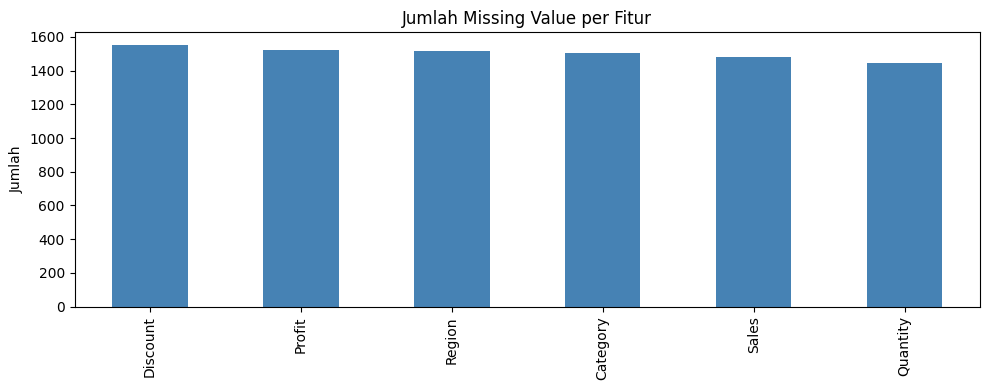

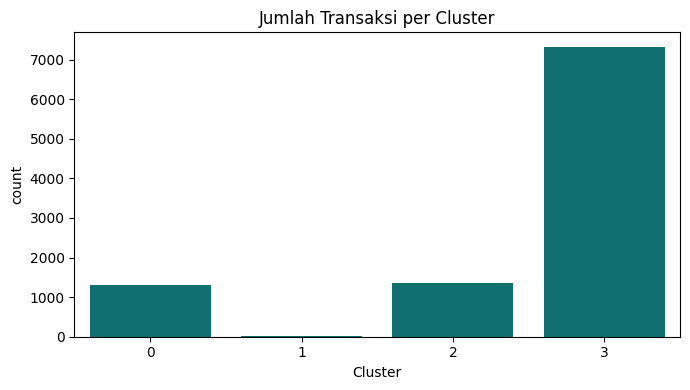

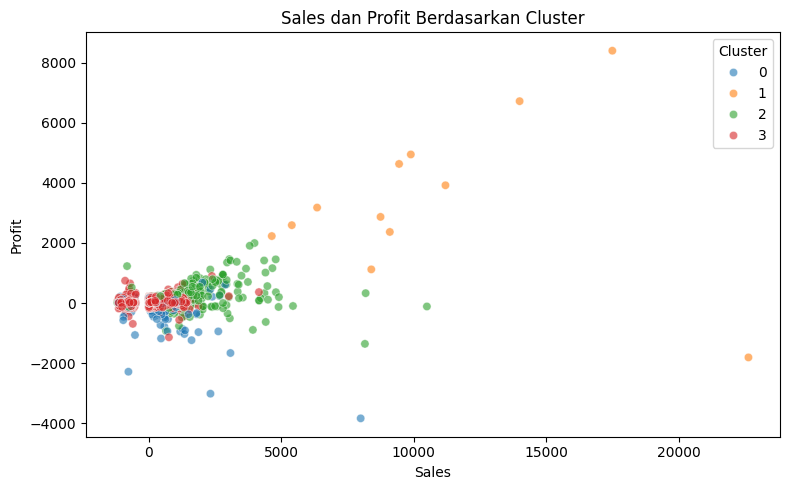

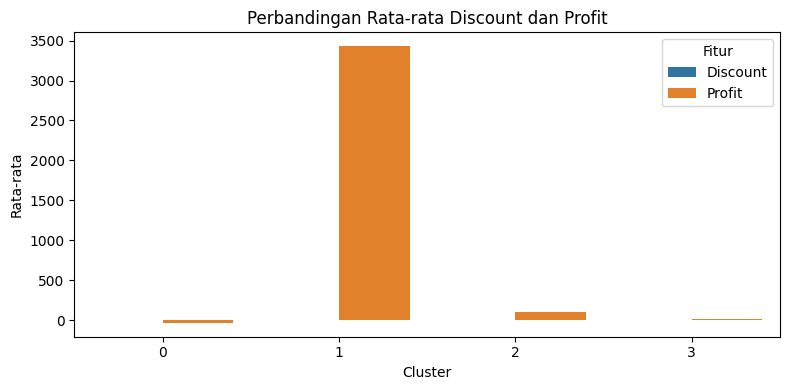

In [14]:
# Tabel perbandingan sebelum dan sesudah preprocessing
perbandingan = pd.DataFrame({
    'Indikator': ['Jumlah baris', 'Jumlah kolom awal', 'Jumlah missing value fitur model', 'Jumlah duplikat'],
    'Sebelum preprocessing': [len(df_awal), df_awal.shape[1], int(df_awal[fitur].isna().sum().sum()), int(df_awal.duplicated().sum())],
    'Sesudah preprocessing': [len(df), df[fitur].shape[1], 0, 0]
})
display(perbandingan)
perbandingan.to_csv('tabel_perbandingan_preprocessing.csv', index=False)

# Tabel statistik dan profil cluster
display(df[fitur_numerik].describe().round(2))
display(profil_cluster)

# Grafik missing value
missing = df[fitur].isna().sum().sort_values(ascending=False)
plt.figure(figsize=(10, 4))
missing.plot(kind='bar', color='steelblue')
plt.title('Jumlah Missing Value per Fitur')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.savefig('gambar_missing_value.png', dpi=150)
plt.show()

# Distribusi cluster
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Cluster', color='teal')
plt.title('Jumlah Transaksi per Cluster')
plt.tight_layout()
plt.savefig('gambar_jumlah_cluster.png', dpi=150)
plt.show()

# Scatter Sales dan Profit
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Sales', y='Profit', hue='Cluster', palette='tab10', alpha=0.6)
plt.title('Sales dan Profit Berdasarkan Cluster')
plt.tight_layout()
plt.savefig('gambar_sales_profit_cluster.png', dpi=150)
plt.show()

# Perbandingan Discount dan Profit
profil_plot = df.groupby('Cluster')[['Discount', 'Profit']].mean().reset_index()
profil_long = profil_plot.melt(id_vars='Cluster', var_name='Fitur', value_name='Rata-rata')
plt.figure(figsize=(8, 4))
sns.barplot(data=profil_long, x='Cluster', y='Rata-rata', hue='Fitur')
plt.title('Perbandingan Rata-rata Discount dan Profit')
plt.tight_layout()
plt.savefig('gambar_discount_profit_cluster.png', dpi=150)
plt.show()

## 11. Ekspor Hasil

Dataset, tabel profil, dan gambar hasil analisis disimpan untuk digunakan dalam laporan.

In [15]:
output_file = "superstore_hasil_preprocessing_clustering.csv"
df.to_csv(output_file, index=False)
profil_cluster.to_csv("tabel_profil_cluster.csv")
files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Kesimpulan Implementasi

Implementasi menghasilkan tabel, gambar, dan file CSV. Output aktual harus dibaca dan dijelaskan pada Bab IV laporan berdasarkan hasil notebook yang dijalankan.